In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score

import skfuzzy as fuzz

print("Library berhasil diimpor!")

Library berhasil diimpor!


In [4]:
# Mengambil data hasil preprocessing
X_fcm = pd.read_csv(
    "../dataset/laptop_features_scaled.csv"
)

# Memastikan data berhasil dimuat
print("Data preprocessing berhasil dimuat!")
print("Ukuran data:", X_fcm.shape)

display(X_fcm.head())

# FCM membutuhkan array dengan format:
# (jumlah fitur, jumlah data)
data_fcm = X_fcm.to_numpy().T

print("\nUkuran data untuk FCM:", data_fcm.shape)
print("Jumlah data:", data_fcm.shape[1])
print("Jumlah fitur:", data_fcm.shape[0])

Data preprocessing berhasil dimuat!
Ukuran data: (1303, 7)


,Price_euros,Ram_GB,Weight_kg,SSD_GB,HDD_GB,CPU_Family_Score,CPU_Base_GHz
0,0.573361,0.357182,0.169576,0.701024,0.0,0.666667,0.518519
1,0.461116,0.357182,0.162095,0.000000,0.0,0.666667,0.333333
2,0.335465,0.357182,0.291771,0.800450,0.0,0.666667,0.592593
3,0.753120,0.563956,0.284289,0.900155,0.0,1.000000,0.666667
4,0.657037,0.357182,0.169576,0.800450,0.0,0.666667,0.814815



Ukuran data untuk FCM: (7, 1303)
Jumlah data: 1303
Jumlah fitur: 7


In [5]:
# Parameter Fuzzy C-Means

n_clusters = 4
m = 2.0
error = 0.005
maxiter = 1000
seed = 42

print("Parameter FCM:")
print("Jumlah cluster:", n_clusters)
print("Fuzziness (m):", m)
print("Error tolerance:", error)
print("Maksimum iterasi:", maxiter)
print("Random seed:", seed)

Parameter FCM:
Jumlah cluster: 4
Fuzziness (m): 2.0
Error tolerance: 0.005
Maksimum iterasi: 1000
Random seed: 42


In [6]:

# Menjalankan algoritma Fuzzy C-Means

cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data=data_fcm,
    c=n_clusters,
    m=m,
    error=error,
    maxiter=maxiter,
    init=None,
    seed=seed
)

print("Proses Fuzzy C-Means berhasil!")
print("--------------------------------")
print("Ukuran cluster centers:", cntr.shape)
print("Ukuran membership matrix:", u.shape)
print("Jumlah iterasi:", len(jm))
print("Fuzzy Partition Coefficient (FPC):", fpc)
print("Nilai objektif akhir:", jm[-1])


Proses Fuzzy C-Means berhasil!
--------------------------------
Ukuran cluster centers: (4, 7)
Ukuran membership matrix: (4, 1303)
Jumlah iterasi: 88
Fuzzy Partition Coefficient (FPC): 0.6351742991028878
Nilai objektif akhir: 121.82506263654746


In [7]:

# Menentukan cluster berdasarkan membership tertinggi

cluster_labels = np.argmax(u, axis=0)

# Menambahkan label cluster ke dataset
df_clustered = X_fcm.copy()
df_clustered["Cluster"] = cluster_labels

# Menambahkan nilai membership setiap cluster
membership_df = pd.DataFrame(
    u.T,
    columns=[f"Membership_Cluster_{i+1}" for i in range(n_clusters)]
)

df_clustered = pd.concat(
    [df_clustered, membership_df],
    axis=1
)

# Mengubah label menjadi 1, 2, 3, dan 4
df_clustered["Cluster"] = df_clustered["Cluster"] + 1

print("Distribusi jumlah laptop setiap cluster:")
display(
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="Jumlah Laptop")
)

print("\nContoh hasil clustering:")
display(df_clustered.head(10))


Distribusi jumlah laptop setiap cluster:


,Jumlah Laptop
Cluster,
1,377
2,120
3,608
4,198



Contoh hasil clustering:


,Price_euros,Ram_GB,Weight_kg,SSD_GB,HDD_GB,CPU_Family_Score,CPU_Base_GHz,Cluster,Membership_Cluster_1,Membership_Cluster_2,Membership_Cluster_3,Membership_Cluster_4
0,0.573361,0.357182,0.169576,0.701024,0.000000,0.666667,0.518519,3,0.029546,0.049878,0.880730,0.039846
1,0.461116,0.357182,0.162095,0.000000,0.000000,0.666667,0.333333,2,0.215166,0.422223,0.247747,0.114864
2,0.335465,0.357182,0.291771,0.800450,0.000000,0.666667,0.592593,3,0.043088,0.071337,0.824008,0.061568
3,0.753120,0.563956,0.284289,0.900155,0.000000,1.000000,0.666667,3,0.049493,0.053462,0.783319,0.113726
4,0.657037,0.357182,0.169576,0.800450,0.000000,0.666667,0.814815,3,0.051400,0.068501,0.797965,0.082134
5,0.233488,0.166080,0.351621,0.000000,0.815281,0.333333,0.777778,1,0.746322,0.107910,0.058468,0.087300
6,0.705167,0.563956,0.336658,0.000000,0.000000,1.000000,0.481481,3,0.228020,0.214794,0.358548,0.198638
7,0.532524,0.357182,0.162095,0.000000,0.000000,0.666667,0.333333,2,0.217550,0.402813,0.259575,0.120062
8,0.604226,0.563956,0.152120,0.900155,0.000000,1.000000,0.333333,3,0.056108,0.070390,0.765764,0.107737
9,0.417571,0.357182,0.226933,0.800450,0.000000,0.666667,0.259259,3,0.065870,0.130756,0.716659,0.086716


In [8]:

# Evaluasi kualitas clustering FCM

# Mengambil label cluster (0 sampai 3)
labels = cluster_labels

# Silhouette Score
sil_score = silhouette_score(
    X_fcm,
    labels
)

# Davies-Bouldin Index
dbi_score = davies_bouldin_score(
    X_fcm,
    labels
)

# Calinski-Harabasz Index
chi_score = calinski_harabasz_score(
    X_fcm,
    labels
)

print("Hasil Evaluasi Fuzzy C-Means")
print("--------------------------------")
print(f"Silhouette Score        : {sil_score:.4f}")
print(f"Davies-Bouldin Index    : {dbi_score:.4f}")
print(f"Calinski-Harabasz Index : {chi_score:.4f}")


Hasil Evaluasi Fuzzy C-Means
--------------------------------
Silhouette Score        : 0.5047
Davies-Bouldin Index    : 0.7592
Calinski-Harabasz Index : 1225.9218


In [10]:
feature_columns = [
    "Price_euros",
    "Ram_GB",
    "Weight_kg",
    "SSD_GB",
    "HDD_GB",
    "CPU_Family_Score",
    "CPU_Base_GHz"
]

cluster_profile = df_clustered.groupby("Cluster")[feature_columns].mean()

print("Rata-rata fitur setiap cluster:")
display(cluster_profile.round(3))

Rata-rata fitur setiap cluster:


,Price_euros,Ram_GB,Weight_kg,SSD_GB,HDD_GB,CPU_Family_Score,CPU_Base_GHz
Cluster,,,,,,,
1,0.348,0.249,0.380,0.004,0.880,0.542,0.492
2,0.246,0.175,0.199,0.231,0.004,0.126,0.231
3,0.550,0.371,0.271,0.807,0.000,0.792,0.555
4,0.606,0.479,0.536,0.764,0.915,0.918,0.629


In [11]:
print(df_clustered.columns.tolist())

['Price_euros', 'Ram_GB', 'Weight_kg', 'SSD_GB', 'HDD_GB', 'CPU_Family_Score', 'CPU_Base_GHz', 'Cluster', 'Membership_Cluster_1', 'Membership_Cluster_2', 'Membership_Cluster_3', 'Membership_Cluster_4']


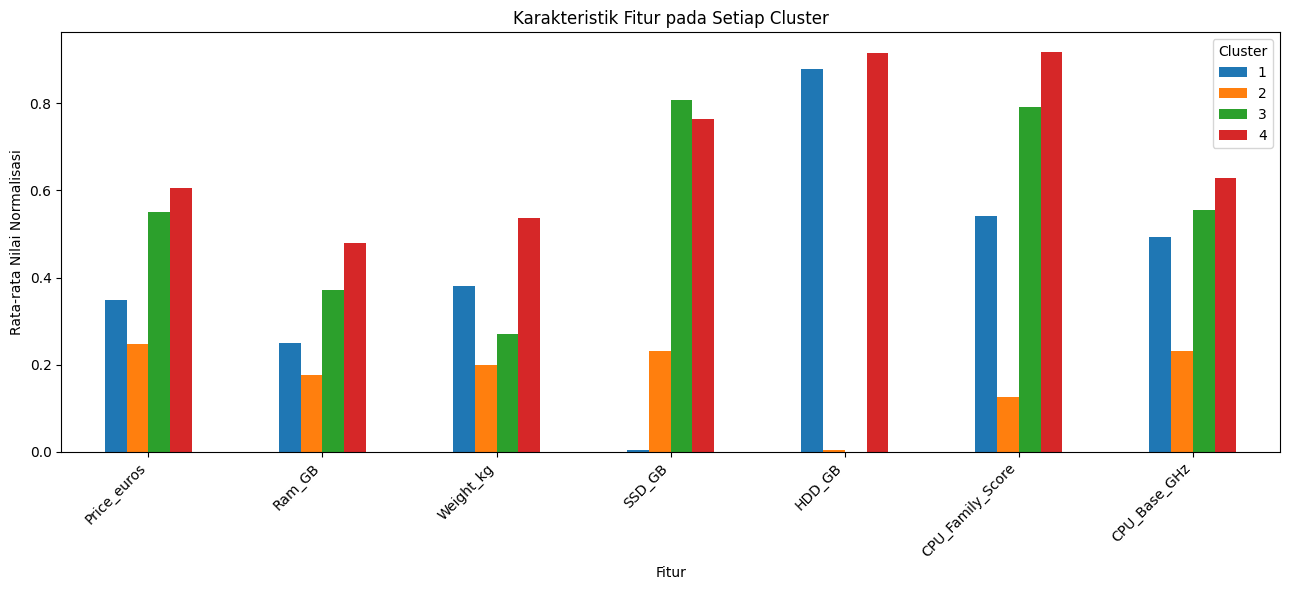

In [12]:

# Visualisasi karakteristik cluster

cluster_profile.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Karakteristik Fitur pada Setiap Cluster")
plt.xlabel("Fitur")
plt.ylabel("Rata-rata Nilai Normalisasi")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [13]:

# Menyimpan hasil clustering untuk digunakan pada Notebook 04

import numpy as np

# Simpan data fitur beserta label cluster dan membership degree
df_clustered.to_csv(
    "../dataset/laptop_fcm_results.csv",
    index=False
)

# Simpan cluster centers FCM
np.save(
    "../dataset/fcm_centers.npy",
    cntr
)

print("Hasil FCM berhasil disimpan!")
print("Data clustering:", df_clustered.shape)
print("Cluster centers:", cntr.shape)


Hasil FCM berhasil disimpan!
Data clustering: (1303, 12)
Cluster centers: (4, 7)
